# Inductive biases for transitive inference
Now that we have a geometric solution for transitive inference in `geometric_solution.ipynb`, how can we bias our networks to learn this solution? In this notebook, we'll bias them to learn stimulus embeddings that lie on the unit circle. In effect, if the only parameter the network can tune is the angle of the embedding, then perhaps the network is biased towards learning a solution that generalizes.

## Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import seaborn as sns
from tqdm import tqdm

from relational_attention.tasks import TransitiveInferenceDataset

In [2]:
torch.manual_seed(42)

## Build task

In [3]:
# Parameters
num_samples = 1000
num_items = 10

In [4]:
# Training task
dataset_train = TransitiveInferenceDataset(num_samples=num_samples, num_items=num_items)
loader_train = DataLoader(dataset_train, batch_size=16, shuffle=True)

In [5]:
# Testing task
dataset_test = TransitiveInferenceDataset(num_samples=num_samples, num_items=num_items, train=False)
loader_test = DataLoader(dataset_test, batch_size=16, shuffle=True)

## Build models

### Minimal model

In [6]:
class RelationalAttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim):
        super().__init__()
        # Initialize weights
        self.W_q = nn.Linear(embed_dim, head_dim, bias=False)
        self.W_k = nn.Linear(embed_dim, head_dim, bias=False)

    def forward(self, x_1, x_2):
        """
        x_1: (batch, embed_dim)
        x_2: (batch, embed_dim)
        returns: (batch, seq_len, head_dim)
        """
        Q = self.W_q(x_2)                            # (B, D)
        K = self.W_k(x_1)                            # (B, D)

        # Compute attention scores over the *learned* Value slots
        attn_weights = torch.matmul(Q, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
        return attn_weights.flatten()

### Normalized model

In [7]:
class UnitNormLinear(nn.Module):
    def __init__(self, in_features, out_features, dim_to_normalize=0, bias=False, eps=1e-8):
        super().__init__()
        self.weight_raw = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.bias = nn.Parameter(torch.zeros(out_features)) if bias else None
        self.dim = dim_to_normalize  # 0 = rows, 1 = columns
        self.eps = eps

    def forward(self, x):
        # weight_raw shape: (out_features, in_features)
        # Normalize along chosen dim
        w = self.weight_raw
        norm = w.norm(dim=self.dim, keepdim=True).clamp_min(self.eps)
        w_hat = w / norm

        # Standard linear: x @ W^T
        out = x @ w_hat.t()
        if self.bias is not None:
            out = out + self.bias
        return out

In [8]:
class RelationalNormAttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim):
        super().__init__()
        # Initialize weights
        self.W_q = UnitNormLinear(embed_dim, head_dim, dim_to_normalize=1, bias=False)
        self.W_k = UnitNormLinear(embed_dim, head_dim, dim_to_normalize=1, bias=False)

    def forward(self, x_1, x_2):
        """
        x_1: (batch, embed_dim)
        x_2: (batch, embed_dim)
        returns: (batch, seq_len, head_dim)
        """
        Q = self.W_q(x_2)                            # (B, D)
        K = self.W_k(x_1)                            # (B, D)

        # Compute attention scores over the *learned* Value slots
        attn_weights = torch.matmul(Q, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
        return attn_weights.flatten()

### Norm penalty model

In [9]:
def unit_norm_penalty(W, dim=1):
    # W shape: (out, in) – encourage columns to be unit norm if dim=0, rows if dim=1
    norms = W.norm(dim=dim)
    return ((norms - 1.0) ** 2).mean()

In [10]:
def train_model_penalty(
    model,
    data_loader,
    lambda_u=1e-3,
    penalty=False,
    optimizer=None,
    loss_fn=None,
    epochs=10,
    device=None,
    return_history=True,
    verbose=True,
):
    """
    Generic training loop with tqdm progress bar.

    Args:
        model (nn.Module): PyTorch model to train.
        data_loader (DataLoader): Iterable providing (X, y) batches.
        optimizer (torch.optim.Optimizer, optional): Optimizer instance.
            If None, defaults to Adam(model.parameters()).
        loss_fn (callable, optional): Loss function.
            If None, defaults to BCEWithLogitsLoss.
        epochs (int): Number of training epochs.
        device (torch.device, optional): Device for computation.
            If None, inferred from model or defaults to CPU.
        return_history (bool): Whether to return the list of losses per epoch.
        verbose (bool): Whether to show tqdm progress bar.

    Returns:
        list[float]: Average loss per epoch (if return_history=True).
    """
    # Defaults
    device = device or next(model.parameters()).device
    optimizer = optimizer or torch.optim.Adam(model.parameters())
    loss_fn = loss_fn or torch.nn.BCEWithLogitsLoss()

    # Put model in training mode
    model.train()

    loss_history = []

    # Optionally wrap tqdm
    progress = range(epochs)
    if verbose:
        progress = tqdm(progress, desc="Training", total=epochs, leave=True)

    for epoch in progress:
        total_loss = 0.0

        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()

            preds = model(X[:,0:1,:], X[:,1:2,:])
            loss_main = loss_fn(preds, y)

            if penalty:
                penalty = unit_norm_penalty(model.W_q.weight, dim=0) \
                        + unit_norm_penalty(model.W_k.weight, dim=0)
                loss = loss_main + lambda_u * penalty
            else:
                loss = loss_main
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(data_loader)
        loss_history.append(avg_loss)

        # Update progress bar if active
        if verbose:
            progress.set_postfix({"loss": f"{avg_loss:.4f}"})

    if verbose:
        progress.close()

    return loss_history if return_history else None

### Rotation model

In [11]:
class RotationalAttention(nn.Module):
    """
    Relational attention head with a 2D rotation inductive bias:
        K = W(x1)
        Q = W(x2) @ R(theta)^T   (i.e., rotate the projected query vectors)

    Assumes head_dim == 2.
    Returns a scalar per example (dot product / sqrt(2)) or you can return the raw dot product.
    """
    def __init__(self, embed_dim, init_theta=0.0, learn_theta=True):
        super().__init__()
        self.head_dim = 2
        self.W = nn.Linear(embed_dim, self.head_dim, bias=False)

        theta = torch.tensor(float(init_theta))
        self.theta = nn.Parameter(theta) if learn_theta else theta

    def rotation_matrix(self):
        # R(theta) in R^{2x2}
        c = torch.cos(self.theta)
        s = torch.sin(self.theta)
        R = torch.stack([
            torch.stack([c, -s]),
            torch.stack([s,  c])
        ])
        return R  # (2,2)

    def forward(self, x_1, x_2):
        K = self.W(x_1)   # (B, 2)
        Q = self.W(x_2)   # (B, 2)

        R = self.rotation_matrix()      # (2,2)
        Q_rot = Q @ R.T                 # rotate queries

        attn_weights = torch.matmul(Q_rot, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
        return attn_weights.flatten()

## Initialize models

In [12]:
# Base model with no changes
model_base = RelationalAttentionHead(num_items, 2)

In [13]:
# Model constrained to unit vector weights
model_norm = RelationalNormAttentionHead(num_items, 2)

In [14]:
# Base model with penalty on weight norms
model_penalty = RelationalAttentionHead(num_items, 2)

In [15]:
# Model with rotation on the query entries
model_rotation = RotationalAttention(num_items)

## Train models

In [16]:
lr = 1e-3
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 250

In [17]:
optimizer = torch.optim.Adam(model_base.parameters(), lr=lr)
loss_base = train_model_penalty(model_base, loader_train, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:05<00:00, 47.39it/s, loss=0.0000]


In [18]:
optimizer = torch.optim.Adam(model_norm.parameters(), lr=lr)
loss_norm = train_model_penalty(model_norm, loader_train, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:06<00:00, 37.48it/s, loss=0.6209]


In [19]:
optimizer = torch.optim.Adam(model_penalty.parameters(), lr=lr)
loss_penalty = train_model_penalty(model_penalty, loader_train, penalty=True, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:07<00:00, 34.40it/s, loss=0.0101]


In [20]:
optimizer = torch.optim.Adam(model_rotation.parameters(), lr=lr)
loss_rotation = train_model_penalty(model_rotation, loader_train, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:06<00:00, 38.24it/s, loss=0.0000]


## Evaluate models

In [21]:
def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for X, y in loader:
            logits = model(X[:,0:1,:], X[:,1:2,:])
            preds = (torch.sigmoid(logits) > 0.5)

            correct += (preds == y).sum().item()
            total += y.size(0)

    return correct / total

In [22]:
acc_base = evaluate_model(model_base, loader_test)
acc_norm = evaluate_model(model_norm, loader_test)
acc_penalty = evaluate_model(model_penalty, loader_test)
acc_rotation = evaluate_model(model_rotation, loader_test)

print("Base model:", acc_base)
print("Enforced norm weights:", acc_norm)
print("Norm penalty:", acc_penalty)
print("Rotated queries:", acc_rotation)

Base model: 0.416
Enforced norm weights: 0.45
Norm penalty: 0.388
Rotated queries: 0.359


## Analyze rotation model

In [23]:
model_rotation.theta

Parameter containing:
tensor(-1.5777, requires_grad=True)

In [24]:
Q_weights = model_rotation.W.weight.data
K_weights = model_rotation.W.weight.data

Q_weights = model_rotation.rotation_matrix() @ Q_weights

In [25]:
sim_qk = (Q_weights.T @ K_weights) / (K_weights.size(-1) ** 0.5)
sim_qk.shape

torch.Size([10, 10])

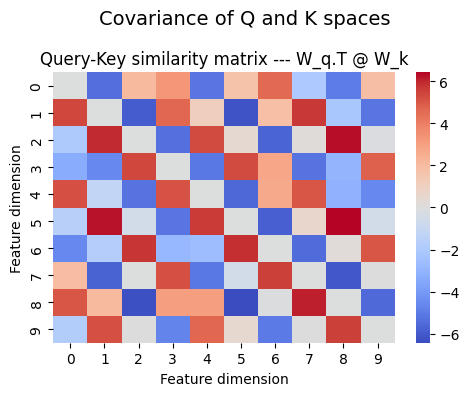

In [26]:
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
sns.heatmap(sim_qk.detach().numpy(), cmap="coolwarm", center=0, ax=ax)
ax.set_title("Query-Key similarity matrix --- W_q.T @ W_k")

ax.set_xlabel("Feature dimension")
ax.set_ylabel("Feature dimension")

plt.suptitle("Covariance of Q and K spaces", fontsize=14)
plt.tight_layout()
plt.show()

In [27]:
Q_weights = Q_weights.detach().numpy()
K_weights = K_weights.detach().numpy()

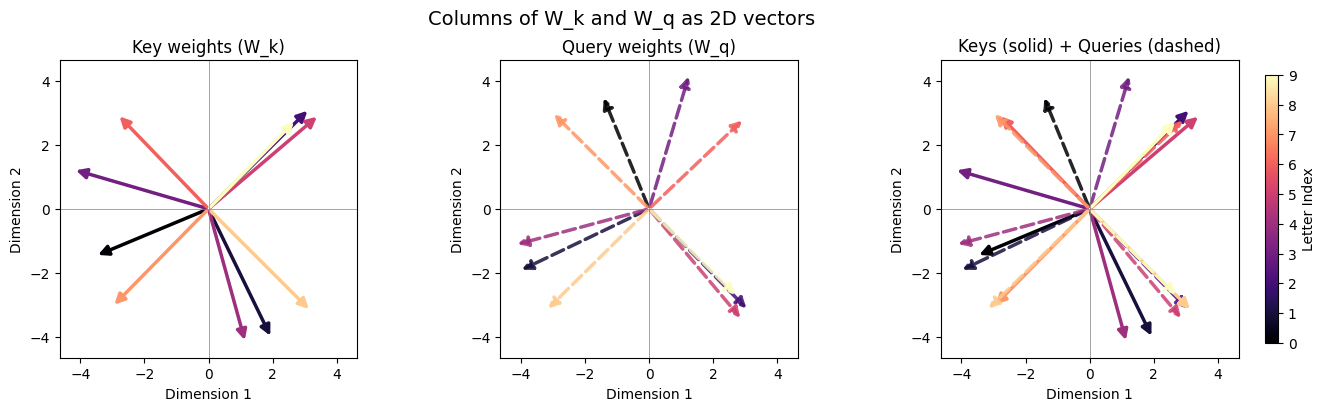

In [28]:
# Expect W_q, W_k as np.ndarray with shape (2, D)
assert Q_weights.shape[0] == 2 and K_weights.shape[0] == 2
assert Q_weights.shape[1] == K_weights.shape[1]
D = Q_weights.shape[1]

cmap = cm.magma
norm = Normalize(vmin=0, vmax=D - 1)

# Shared limits across all panels
lim = 1.1 * max(np.abs(Q_weights).max(), np.abs(K_weights).max())

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

# Common axis formatting helper (inline)
for ax in axes:
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.set_aspect("equal")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

# --- Panel 1: Keys only ---
ax = axes[0]
for i in range(D):
    color = cmap(norm(i))
    kx, ky = K_weights[:, i]
    ax.add_patch(
        FancyArrowPatch(
            (0, 0), (kx, ky),
            arrowstyle='-|>',
            mutation_scale=15,
            linewidth=2.5,
            color=color
        )
    )
ax.set_title("Key weights (W_k)")

# --- Panel 2: Queries only ---
ax = axes[1]
for i in range(D):
    color = cmap(norm(i))
    qx, qy = Q_weights[:, i]
    ax.add_patch(
        FancyArrowPatch(
            (0, 0), (qx, qy),
            arrowstyle='-|>',
            mutation_scale=15,
            linewidth=2.5,
            linestyle='--',
            color=color,
            alpha=0.85
        )
    )
ax.set_title("Query weights (W_q)")

# --- Panel 3: Keys + Queries ---
ax = axes[2]
for i in range(D):
    color = cmap(norm(i))

    # Keys (solid)
    kx, ky = K_weights[:, i]
    ax.add_patch(
        FancyArrowPatch(
            (0, 0), (kx, ky),
            arrowstyle='-|>',
            mutation_scale=15,
            linewidth=2.5,
            color=color
        )
    )

    # Queries (dashed)
    qx, qy = Q_weights[:, i]
    ax.add_patch(
        FancyArrowPatch(
            (0, 0), (qx, qy),
            arrowstyle='-|>',
            mutation_scale=15,
            linewidth=2.5,
            linestyle='--',
            color=color,
            alpha=0.85
        )
    )
ax.set_title("Keys (solid) + Queries (dashed)")

# --- Single shared colorbar (by column index) ---
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, pad=0.02, shrink=0.9)
cbar.set_label("Letter Index")

fig.suptitle("Columns of W_k and W_q as 2D vectors", fontsize=14)
plt.show()